# **Ingeniería de Datos y Extracción de Trazas**

**Proyecto:** Automatización de Cámara de Niebla - Laboratorio Avanzado

### Objetivo
Transformar la información cruda (videos experimentales continuos de referencia) en un conjunto de datos discreto (imágenes individuales de partículas) que servirá como base para entrenar nuestra Red Neuronal.

### Flujo de Trabajo:
Implementamos un algoritmo de visión artificial que realiza la detección de eventos mediante:
1.  **Pre-procesamiento:** Reducción de ruido térmico del sensor.
2.  **Umbralización:** Separación de trazas brillantes del fondo oscuro.
3.  **Segmentación:** Recorte automático de regiones de interés (ROIs).

## 1. Configuración del Entorno y Carga de Datos Crudos

En esta sección, importamos las librerías necesarias de visión por computadora (`OpenCV`) y gestión de archivos. Además, automatizamos la descarga del material experimental clonando el repositorio del proyecto desde GitHub.

Esto asegura que trabajamos con el archivo de video original `Videopruebas1.mp4`, garantizando la **reproducibilidad** del experimento sin necesidad de subir archivos manualmente.

In [ ]:
import cv2
import numpy as np
import os
import shutil
import glob
from google.colab.patches import cv2_imshow # Solo para visualizar ejemplos

# --- CLONAR REPOSITORIO ---
GITHUB_USER = "xevasme"
GITHUB_REPO = "Laboratorio_Avanzado"
GITHUB_URL = f"https://github.com/{GITHUB_USER}/{GITHUB_REPO}.git"
NOMBRE_REPO = "Laboratorio_Repo"

if os.path.exists(NOMBRE_REPO):
    shutil.rmtree(NOMBRE_REPO)

print(f"🔄 Descargando video de prueba desde GitHub...")
!git clone {GITHUB_URL} {NOMBRE_REPO}

# Definir la ruta exacta del video base (Videopruebas1.mp4)
# Según tu estructura: Datos/ProyectoFinal/MaterialPrueba/Videopruebas1.mp4
RUTA_VIDEO_BASE = os.path.join(NOMBRE_REPO, "Datos", "ProyectoFinal", "MaterialPrueba", "Videopruebas1.mp4")

if os.path.exists(RUTA_VIDEO_BASE):
    print(f"✅ Video encontrado: {RUTA_VIDEO_BASE}")
else:
    print(f"❌ ERROR: No se encuentra el video en la ruta especificada.")

🔄 Descargando video de prueba desde GitHub...
Cloning into 'Laboratorio_Repo'...
remote: Enumerating objects: 545, done.
remote: Counting objects: 100% (275/275), done.
remote: Compressing objects: 100% (254/254), done.
remote: Total 545 (delta 48), reused 4 (delta 4), pack-reused 270 (from 1)
Receiving objects: 100% (545/545), 44.23 MiB | 27.46 MiB/s, done.
Resolving deltas: 100% (75/75), done.
✅ Video encontrado: Laboratorio_Repo/Datos/ProyectoFinal/MaterialPrueba/Videopruebas1.mp4


## 2. Pipeline de Procesamiento: Detección y Binarización

Esta función implementa el núcleo del algoritmo de extracción. A diferencia de un enfoque simple, utilizamos un **proceso de doble umbral** para garantizar la máxima nitidez en las trazas:

1.  **Pre-procesamiento:** Suavizado Gaussiano `(5,5)` para reducir el ruido térmico del sensor.
2.  **Detección (Umbral 1):** Aplicamos un umbral de sensibilidad (**195**) para localizar cualquier evento brillante sobre el fondo oscuro.
3.  **Morfología:** Dilatación (`kernel 15px`) para unificar trazas que podrían aparecer fragmentadas (ej. partículas Beta largas).
4.  **Limpieza Final (Binarización):** Una vez recortada la región de interés (ROI), aplicamos un **segundo umbral estricto (200)** sobre el recorte.
    * *Objetivo:* Convertir la imagen a blanco y negro puro (Binaria), eliminando bordes difusos o grises. Esto genera imágenes de alto contraste ideales para la red neuronal.

**Salida de Datos:**
Las imágenes se guardan siguiendo la nomenclatura estandarizada: `traza_frame_{N}_crop{M}.jpg`, lo que permite rastrear exactamente en qué momento del video ocurrió cada evento.

In [ ]:
def generar_candidatos_dataset(video_path, output_folder="Dataset_Sin_Clasificar"):
    # 1. Preparar entorno
    if os.path.exists(output_folder):
        shutil.rmtree(output_folder)
    os.makedirs(output_folder)

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("❌ Error: No se pudo cargar el video.")
        return

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"⚙️ Iniciando extracción en: {os.path.basename(video_path)}")

    # Kernel para "engrosar" las trazas
    kernel_dilatacion = np.ones((15, 15), np.uint8)

    # Contadores
    frame_idx = 0
    trazas_totales = 0

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret: break

        # --- ETAPA 1: DETECCIÓN ---
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        blurred = cv2.GaussianBlur(gray, (5, 5), 0)

        # Umbral inicial para DETECTAR (valor 195)
        _, thresh = cv2.threshold(blurred, 195, 255, cv2.THRESH_BINARY)

        # Dilatación para unir trazas fragmentadas
        dilated = cv2.dilate(thresh, kernel_dilatacion, iterations=1)

        contours, _ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        # --- ETAPA 2: EXTRACCIÓN Y LIMPIEZA FINAL ---
        crop_count_frame = 0 # Contador de trazas dentro de ESTE frame

        for cnt in contours:
            area = cv2.contourArea(cnt)

            # Filtro de Área (300px)
            if area > 300:
                x, y, w, h = cv2.boundingRect(cnt)

                # Padding (Margen) de 5px
                pad = 5
                y1 = max(0, y - pad)
                y2 = min(frame.shape[0], y + h + pad)
                x1 = max(0, x - pad)
                x2 = min(frame.shape[1], x + w + pad)

                # Recorte inicial en GRISES
                roi_gray = gray[y1:y2, x1:x2]

                if roi_gray.size > 0:
                    # --- CORRECCIÓN DE CALIDAD (BINARIZACIÓN) ---
                    # Aplicamos el umbral fuerte (200) para dejar solo Blanco/Negro
                    # Esto replica la calidad nítida de tu compañero.
                    _, roi_binary = cv2.threshold(roi_gray, 200, 255, cv2.THRESH_BINARY)

                    # --- CORRECCIÓN DE NOMBRE ---
                    # Formato idéntico al de tu compañero: traza_frame_XXX_cropYY.jpg
                    filename = f"{output_folder}/traza_frame_{frame_idx}_crop{crop_count_frame:02d}.jpg"

                    cv2.imwrite(filename, roi_binary)

                    crop_count_frame += 1
                    trazas_totales += 1

        frame_idx += 1
        if frame_idx % 100 == 0:
            print(f"   ... Procesando frame {frame_idx}/{total_frames}")

    cap.release()
    print(f"\n✅ Ingeniería de datos finalizada.")
    print(f"📊 Se extrajeron {trazas_totales} imágenes limpias.")

    shutil.make_archive('Dataset_Base_Binario', 'zip', output_folder)
    print(f"📦 Archivo 'Dataset_Base_Binario.zip' listo para descargar.")

## 3. Ejecución de la Extracción y Validación Visual

Ejecutamos el algoritmo sobre el video de prueba. El sistema recorrerá el video frame a frame, extraerá cada evento detectado y lo guardará como una imagen independiente `.jpg`.

**Salida Esperada:**
* Se generará una carpeta `Dataset_Sin_Clasificar` con todas las detecciones.
* Se creará un archivo `.zip` listo para descargar.
* **Nota:** Este dataset es la "materia prima" que posteriormente será clasificada manualmente por el equipo (en *Alpha*, *Beta* y *Ruido*) para crear la base de datos de entrenamiento del modelo.

⚙️ Iniciando extracción en: Videopruebas1.mp4
   ... Procesando frame 100/496
   ... Procesando frame 200/496
   ... Procesando frame 300/496
   ... Procesando frame 400/496

✅ Ingeniería de datos finalizada.
📊 Se extrajeron 11632 imágenes limpias.
📦 Archivo 'Dataset_Base_Binario.zip' listo para descargar.

--- Muestras Aleatorias del Dataset Generado ---


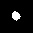

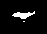

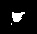

In [ ]:
# Ejecutar la función
generar_candidatos_dataset(RUTA_VIDEO_BASE)

# (Opcional) Visualizar algunas muestras extraídas para validar calidad
print("\n--- Muestras Aleatorias del Dataset Generado ---")
muestras = glob.glob("Dataset_Sin_Clasificar/*.jpg")[:5] # Ver 5 imágenes
for m in muestras:
    img = cv2.imread(m)
    cv2_imshow(img)